In [5]:
# =============================================================================
# Cell 1: Environment Setup, Google Drive Mounting, and Directory Tree
# =============================================================================
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, io, sys, time, json, hashlib, zipfile, requests, warnings
from datetime import datetime, timezone
import pandas as pd
import numpy as np

# Install required scalable data engineering libraries
!pip install -q pyspark==3.5.1 pyarrow airportsdata requests pandas numpy matplotlib

import airportsdata
import pyspark
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.sql.window import Window

# Define Persistent Storage Directory directly on Google Drive
PROJECT_DIR = Path('/content/drive/MyDrive/Flight-Delay-Prediction')
PATHS = {
    'bts_raw': PROJECT_DIR / 'data/raw/bts',
    'noaa_raw': PROJECT_DIR / 'data/raw/noaa',
    'interim': PROJECT_DIR / 'data/interim',
    'processed': PROJECT_DIR / 'data/processed',
    'features': PROJECT_DIR / 'data/features',
    'models': PROJECT_DIR / 'models',
    'results': PROJECT_DIR / 'results',
    'benchmarks': PROJECT_DIR / 'benchmarks',
    'logs': PROJECT_DIR / 'logs'
}

for p in PATHS.values():
    p.mkdir(parents=True, exist_ok=True)

# Initialize Optimized Spark Engine for Scale
spark = (SparkSession.builder
         .appName("DA231o_FlightDelay_Master")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "32")
         .config("spark.sql.adaptive.enabled", "true")
         .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
         .config("spark.driver.memory", "8g")
         .config("spark.driver.maxResultSize", "4g")
         .getOrCreate())

spark.sparkContext.setLogLevel("WARN")

TOP_10_AIRPORTS = ['ATL', 'CLT', 'DEN', 'DFW', 'LAS', 'LAX', 'MCO', 'ORD', 'PHX', 'SEA']
AIRPORT_STATIONS = {
    'ATL': 'USW00013874', 'CLT': 'USW00013881', 'DEN': 'USW00003017', 'DFW': 'USW00003927',
    'LAS': 'USW00023169', 'LAX': 'USW00023174', 'MCO': 'USW00012815', 'ORD': 'USW00094846',
    'PHX': 'USW00023183', 'SEA': 'USW00024233'
}

print(f"Spark Version: {spark.version} | PySpark Version: {pyspark.__version__}")
print(f"Persistent storage verified on Google Drive: {PROJECT_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Spark Version: 3.5.1 | PySpark Version: 3.5.1
Persistent storage verified on Google Drive: /content/drive/MyDrive/Flight-Delay-Prediction


In [6]:
# =============================================================================
# Cell 2: Data Acquisition Helper with Checksum Auditing
# =============================================================================
session = requests.Session()
download_manifest = []

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

def get_or_download(url, destination, min_bytes=1000):
    dest = Path(destination)
    if dest.exists() and dest.stat().st_size >= min_bytes:
        download_manifest.append({'url': url, 'file': str(dest), 'bytes': dest.stat().st_size, 'status': 'cached'})
        return dest
    temp = dest.with_suffix(dest.suffix + '.part')
    with session.get(url, stream=True, timeout=(30, 240)) as response:
        response.raise_for_status()
        with open(temp, 'wb') as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
    if temp.stat().st_size < min_bytes:
        temp.unlink(missing_ok=True)
        raise RuntimeError(f"Download failed or truncated: {url}")
    temp.replace(dest)
    download_manifest.append({
        'url': url, 'file': str(dest), 'bytes': dest.stat().st_size,
        'sha256': sha256_file(dest), 'status': 'downloaded'
    })
    return dest

print("Ingestion helper loaded.")

Ingestion helper loaded.


In [7]:
# =============================================================================
# Cell 3: Ingest All 12 Months of BTS and 10 NOAA Stations
# =============================================================================
YEAR = 2025
BTS_BASE = 'https://transtats.bts.gov/PREZIP'
NOAA_BASE = f'https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-year/{YEAR}/psv'

# 1. Download & Extract BTS Monthly ZIPs
bts_csv_files = []
for month in range(1, 13):
    zip_name = f'On_Time_Reporting_Carrier_On_Time_Performance_1987_present_{YEAR}_{month}.zip'
    zip_dest = PATHS['bts_raw'] / f'bts_{YEAR}_{month:02d}.zip'
    csv_dest = PATHS['bts_raw'] / f'bts_{YEAR}_{month:02d}.csv'

    get_or_download(f'{BTS_BASE}/{zip_name}', zip_dest, min_bytes=50_000)
    if not csv_dest.exists() or csv_dest.stat().st_size < 1000:
        with zipfile.ZipFile(zip_dest) as z:
            csv_members = [n for n in z.namelist() if n.lower().endswith('.csv')]
            member = max(csv_members, key=lambda n: z.getinfo(n).file_size)
            with z.open(member) as src, open(csv_dest, 'wb') as dst:
                import shutil
                shutil.copyfileobj(src, dst)
    bts_csv_files.append(str(csv_dest))
    print(f"Validated BTS {YEAR}-{month:02d}")

# 2. Download NOAA GHCNh Weather PSVs
noaa_paths = {}
for airport, station_id in AIRPORT_STATIONS.items():
    filename = f'GHCNh_{station_id}_{YEAR}.psv'
    dest = PATHS['noaa_raw'] / filename
    get_or_download(f'{NOAA_BASE}/{filename}', dest, min_bytes=1000)
    noaa_paths[airport] = dest
    print(f"Validated NOAA station for {airport}")

with open(PATHS['logs'] / 'download_manifest.json', 'w') as f:
    json.dump(download_manifest, f, indent=2)

Validated BTS 2025-01
Validated BTS 2025-02
Validated BTS 2025-03
Validated BTS 2025-04
Validated BTS 2025-05
Validated BTS 2025-06
Validated BTS 2025-07
Validated BTS 2025-08
Validated BTS 2025-09
Validated BTS 2025-10
Validated BTS 2025-11
Validated BTS 2025-12
Validated NOAA station for ATL
Validated NOAA station for CLT
Validated NOAA station for DEN
Validated NOAA station for DFW
Validated NOAA station for LAS
Validated NOAA station for LAX
Validated NOAA station for MCO
Validated NOAA station for ORD
Validated NOAA station for PHX
Validated NOAA station for SEA


In [8]:
# =============================================================================
# Cell 4: Standardize Flights, Apply Closed-Cohort Filter & Save Critical Dataset
# =============================================================================
sample_header = pd.read_csv(bts_csv_files[0], nrows=0).columns.tolist()
tail_col = 'Tail_Number' if 'Tail_Number' in sample_header else 'TailNum'

BTS_COLS = ['FlightDate', 'Reporting_Airline', tail_col, 'Origin', 'Dest',
            'CRSDepTime', 'CRSArrTime', 'DepDelay', 'ArrDelay', 'Cancelled', 'Diverted', 'CRSElapsedTime']

raw_bts = (spark.read.option('header', True).option('inferSchema', True)
           .csv(bts_csv_files)
           .select(*BTS_COLS))

if tail_col != 'Tail_Number':
    raw_bts = raw_bts.withColumnRenamed(tail_col, 'Tail_Number')

flights = (raw_bts
    .withColumn('FlightDate', F.to_date('FlightDate'))
    .withColumn('Origin', F.upper(F.trim('Origin')))
    .withColumn('Dest', F.upper(F.trim('Dest')))
    # Closed-Cohort Selection (Both Origin & Destination in Top 10 Hubs)
    .filter(F.col('Origin').isin(TOP_10_AIRPORTS) & F.col('Dest').isin(TOP_10_AIRPORTS))
    .filter((F.coalesce(F.col('Cancelled'), F.lit(0)) == 0) &
            (F.coalesce(F.col('Diverted'), F.lit(0)) == 0))
    .filter(F.col('DepDelay').isNotNull() & F.col('ArrDelay').isNotNull())
    .withColumn('DepDelay', F.col('DepDelay').cast('double'))
    .withColumn('ArrDelay', F.col('ArrDelay').cast('double'))
    .withColumn('CRSElapsedTime', F.col('CRSElapsedTime').cast('double'))
    .withColumn('CRSDepTime', F.col('CRSDepTime').cast('int'))
    .withColumn('CRSArrTime', F.col('CRSArrTime').cast('int'))
    .withColumn('scheduled_month', F.month('FlightDate'))
    .withColumn('scheduled_day_of_week', F.dayofweek('FlightDate'))
)

cohort_path = PATHS['processed'] / 'bts_cohort_2025.parquet'
flights.write.mode('overwrite').option('compression', 'snappy').parquet(str(cohort_path))
flights = spark.read.parquet(str(cohort_path))
print(f"Persisted Cleaned Closed-Cohort Flights ({flights.count():,} rows) to: {cohort_path}")

Persisted Cleaned Closed-Cohort Flights (465,685 rows) to: /content/drive/MyDrive/Flight-Delay-Prediction/data/processed/bts_cohort_2025.parquet


In [10]:
# =============================================================================
# Cell 5: Standardize NOAA Surface Weather & Save Weather Parquet
# =============================================================================
import shutil

weather_parts = []
weather_cols = ['DATE', 'temperature', 'dew_point_temperature', 'wind_direction',
                'wind_speed', 'visibility', 'sea_level_pressure']

print("Parsing NOAA PSV files...")
for airport, psv_file in noaa_paths.items():
    pdf = pd.read_csv(psv_file, sep='|', usecols=weather_cols, low_memory=False)
    pdf['airport'] = airport

    # 1. Parse as UTC datetime and drop records with invalid dates
    dt_series = pd.to_datetime(pdf['DATE'], errors='coerce', utc=True)
    pdf = pdf.assign(weather_dt=dt_series).dropna(subset=['weather_dt'])

    # 2. Filter for target year
    pdf = pdf[pdf['weather_dt'].dt.year == YEAR]

    # 3. FIX: Convert to explicit ISO string to prevent PyArrow from writing INT64(NANOS)
    pdf['weather_time_str'] = pdf['weather_dt'].dt.strftime('%Y-%m-%d %H:%M:%S')

    for c in weather_cols[1:]:
        pdf[c] = pd.to_numeric(pdf[c], errors='coerce')

    pdf = pdf.drop(columns=['DATE', 'weather_dt'])
    pdf = pdf.sort_values('weather_time_str').drop_duplicates(subset=['airport', 'weather_time_str'], keep='last')
    weather_parts.append(pdf)

weather_all_pd = pd.concat(weather_parts, ignore_index=True)
weather_parquet = PATHS['processed'] / 'noaa_hourly_2025.parquet'

# 4. Remove any existing/corrupted parquet files left on Google Drive from previous runs
if weather_parquet.exists():
    if weather_parquet.is_dir():
        shutil.rmtree(weather_parquet)
    else:
        weather_parquet.unlink()

# 5. Save clean table to Google Drive
weather_all_pd.to_parquet(weather_parquet, index=False, compression='snappy')

# 6. Read into Spark and parse the timestamp natively using Spark SQL
weather_spark = (spark.read.parquet(str(weather_parquet))
                 .withColumn('weather_time_utc', F.to_timestamp('weather_time_str', 'yyyy-MM-dd HH:mm:ss'))
                 .drop('weather_time_str'))

print(f"SUCCESS: Persisted Canonical Weather Table ({weather_spark.count():,} rows) to: {weather_parquet}")

Parsing NOAA PSV files...
SUCCESS: Persisted Canonical Weather Table (130,457 rows) to: /content/drive/MyDrive/Flight-Delay-Prediction/data/processed/noaa_hourly_2025.parquet


In [11]:
# =============================================================================
# Cell 6: UTC Conversion, Rolling Congestion Window & Aircraft Rotation Delay
# =============================================================================
airport_db = airportsdata.load('IATA')
airport_tz = {c: airport_db[c]['tz'] for c in TOP_10_AIRPORTS}

tz_schema = T.StructType([
    T.StructField('Origin', T.StringType(), False),
    T.StructField('origin_tz', T.StringType(), False)
])
tz_df = spark.createDataFrame([(k, v) for k, v in airport_tz.items()], schema=tz_schema)
flights = flights.join(tz_df, on='Origin', how='left')

# Scheduled Local to UTC Conversion
flights = (flights
    .withColumn('dep_hh', F.floor(F.col('CRSDepTime') / 100).cast('int'))
    .withColumn('dep_mm', (F.col('CRSDepTime') % 100).cast('int'))
    .withColumn('sched_dep_local',
        F.to_timestamp(F.concat_ws(' ', F.col('FlightDate').cast('string'),
            F.format_string('%02d:%02d:00', F.when(F.col('dep_hh') == 24, 0).otherwise(F.col('dep_hh')), F.col('dep_mm')))))
    .withColumn('sched_dep_local',
        F.when(F.col('CRSDepTime') == 2400, F.expr('sched_dep_local + INTERVAL 1 DAY')).otherwise(F.col('sched_dep_local')))
    .withColumn('scheduled_departure_utc', F.to_utc_timestamp('sched_dep_local', F.col('origin_tz')))
    .withColumn('t_minus_2_utc', F.expr('scheduled_departure_utc - INTERVAL 2 HOURS'))
    .withColumn('flight_key', F.monotonically_increasing_id())
)

# Feature 1: Rolling 2-Hour Airport Departure Congestion
time_sec = F.col('scheduled_departure_utc').cast('long')
cong_win = Window.partitionBy('Origin').orderBy(time_sec).rangeBetween(-7200, 0)
flights = flights.withColumn('origin_congestion_2h', F.count('flight_key').over(cong_win) - 1)

# Feature 2: Prior-Leg Aircraft Rotation Delay (Strict Past Boundary)
if 'Tail_Number' in flights.columns:
    tail_win = Window.partitionBy('Tail_Number').orderBy('scheduled_departure_utc')
    flights = (flights
        .withColumn('prev_arr_delay', F.lag('ArrDelay', 1).over(tail_win))
        .withColumn('prev_dep_utc', F.lag('scheduled_departure_utc', 1).over(tail_win))
        .withColumn('prior_leg_delay',
            F.when((F.col('prev_dep_utc').isNotNull()) & (F.col('prev_dep_utc') <= F.col('t_minus_2_utc')),
                   F.coalesce(F.col('prev_arr_delay'), F.lit(0.0))).otherwise(0.0)))
else:
    flights = flights.withColumn('prior_leg_delay', F.lit(0.0))

print("Operational features successfully computed.")

Operational features successfully computed.


In [12]:
# =============================================================================
# Cell 7: As-Of Weather Join [T-6h, T-2h] & Aviation Feature Decompositions
# =============================================================================
w_clean = weather_spark.select(
    F.col('airport').alias('w_airport'),
    F.col('weather_time_utc').cast('timestamp').alias('w_time_utc'),
    F.col('temperature').alias('w_temp'),
    F.col('dew_point_temperature').alias('w_dew'),
    F.col('wind_direction').alias('w_wdir'),
    F.col('wind_speed').alias('w_wspeed'),
    F.col('visibility').alias('w_vis'),
    F.col('sea_level_pressure').alias('w_slp')
)

join_cond = (
    (F.col('Origin') == F.col('w_airport')) &
    (F.col('w_time_utc') <= F.col('t_minus_2_utc')) &
    (F.col('w_time_utc') >= F.expr('t_minus_2_utc - INTERVAL 6 HOURS'))
)

matched = flights.join(w_clean, join_cond, 'left')
dedup_win = Window.partitionBy('flight_key').orderBy(F.col('w_time_utc').desc_nulls_last())
joined = matched.withColumn('rn', F.row_number().over(dedup_win)).filter(F.col('rn') == 1).drop('rn')

# Runway Heading Crosswind / Headwind Math
AIRPORT_RUNWAYS = {'ATL': 90.0, 'CLT': 180.0, 'DEN': 170.0, 'DFW': 175.0, 'LAS': 260.0,
                   'LAX': 250.0, 'MCO': 180.0, 'ORD': 270.0, 'PHX': 260.0, 'SEA': 160.0}
runway_map = F.create_map([F.lit(x) for kv in AIRPORT_RUNWAYS.items() for x in kv])
rad = np.pi / 180.0
wind_diff = (F.col('w_wdir') - runway_map[F.col('Origin')]) * F.lit(rad)

features_df = (joined
    .withColumn('scheduled_departure_hour', F.hour('sched_dep_local').cast('double'))
    .withColumn('weather_available', F.col('w_time_utc').isNotNull().cast('int'))
    .withColumn('weather_age_minutes', (F.col('t_minus_2_utc').cast('long') - F.col('w_time_utc').cast('long')) / 60.0)
    .withColumn('weather_crosswind', F.abs(F.col('w_wspeed') * F.sin(wind_diff)))
    .withColumn('weather_headwind', F.col('w_wspeed') * F.cos(wind_diff))
    .withColumn('weather_icing_risk',
        F.when((F.col('w_temp') <= 0.0) & ((F.col('w_temp') - F.col('w_dew')) <= 2.0), 1.0).otherwise(0.0))
    .withColumn('weather_ifr_conditions',
        F.when(F.col('w_vis') < 4800.0, 1.0).otherwise(0.0))
    # Two-Stage Hurdle Labels
    .withColumn('DEP_DEL15', F.when(F.col('DepDelay') >= 15.0, 1.0).otherwise(0.0))
    .withColumn('ARR_DEL15', F.when(F.col('ArrDelay') >= 15.0, 1.0).otherwise(0.0))
    .withColumn('log_DepDelay', F.log1p(F.when(F.col('DepDelay') > 0, F.col('DepDelay')).otherwise(0.0)))
    .withColumn('log_ArrDelay', F.log1p(F.when(F.col('ArrDelay') > 0, F.col('ArrDelay')).otherwise(0.0)))
    # Strict Chronological Partitioning: Jan-Aug train, Sep-Oct val, Nov-Dec test
    .withColumn('data_split',
        F.when(F.month('FlightDate').between(1, 8), 'train')
         .when(F.month('FlightDate').isin(9, 10), 'validation')
         .when(F.month('FlightDate').isin(11, 12), 'test'))
)

# Define Canonical Predictor Sets
bts_feature_cols = ['Origin', 'Dest', 'Reporting_Airline', 'scheduled_month',
                    'scheduled_day_of_week', 'scheduled_departure_hour', 'CRSElapsedTime',
                    'origin_congestion_2h', 'prior_leg_delay']

weather_feature_cols = bts_feature_cols + ['w_temp', 'w_dew', 'w_wspeed', 'w_slp',
                                           'weather_crosswind', 'weather_headwind',
                                           'weather_icing_risk', 'weather_ifr_conditions',
                                           'weather_available', 'weather_age_minutes']

# Save Partitioned Master Feature Sets directly to Google Drive
for task, raw_tgt, log_tgt, cls_tgt in [
    ('departure', 'DepDelay', 'log_DepDelay', 'DEP_DEL15'),
    ('arrival', 'ArrDelay', 'log_ArrDelay', 'ARR_DEL15')
]:
    for variant, p_cols in [('bts_only', bts_feature_cols), ('bts_weather', weather_feature_cols)]:
        out_dir = PATHS['features'] / f"{task}_{variant}"
        meta = ['flight_key', 'FlightDate', 'data_split', raw_tgt, log_tgt, cls_tgt]
        ds = features_df.select(*list(dict.fromkeys(meta + p_cols))).filter(F.col('data_split').isNotNull())
        (ds.write.mode('overwrite')
           .partitionBy('data_split')
           .option('compression', 'snappy')
           .parquet(str(out_dir)))
        print(f"Persisted Partitioned Feature Set: {out_dir}")

Persisted Partitioned Feature Set: /content/drive/MyDrive/Flight-Delay-Prediction/data/features/departure_bts_only
Persisted Partitioned Feature Set: /content/drive/MyDrive/Flight-Delay-Prediction/data/features/departure_bts_weather
Persisted Partitioned Feature Set: /content/drive/MyDrive/Flight-Delay-Prediction/data/features/arrival_bts_only
Persisted Partitioned Feature Set: /content/drive/MyDrive/Flight-Delay-Prediction/data/features/arrival_bts_weather


In [13]:
# =============================================================================
# Cell 8: Controlled Ablation Matrix (LinReg, RF, GBT on Both Targets)
# =============================================================================
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, Imputer, VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

def build_spark_pipeline(predictors, estimator):
    cat_cols = [c for c in predictors if c in ['Origin', 'Dest', 'Reporting_Airline']]
    num_cols = [c for c in predictors if c not in cat_cols]

    idx = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in cat_cols]
    enc = OneHotEncoder(inputCols=[f"{c}_idx" for c in cat_cols], outputCols=[f"{c}_oh" for c in cat_cols], handleInvalid="keep")
    imp = Imputer(strategy="median", inputCols=num_cols, outputCols=[f"{c}_imp" for c in num_cols])
    asm = VectorAssembler(inputCols=[f"{c}_oh" for c in cat_cols] + [f"{c}_imp" for c in num_cols],
                          outputCol="features", handleInvalid="keep")
    return Pipeline(stages=idx + [enc, imp, asm, estimator])

eval_mae = RegressionEvaluator(metricName="mae")
eval_rmse = RegressionEvaluator(metricName="rmse")
eval_r2 = RegressionEvaluator(metricName="r2")

ablation_models = {
    'LinearRegression': LinearRegression(maxIter=25, regParam=0.1),
    'RandomForest': RandomForestRegressor(numTrees=40, maxDepth=8, maxBins=64, seed=42),
    'GBTRegressor': GBTRegressor(maxIter=25, maxDepth=6, maxBins=64, seed=42)
}

ablation_results = []

for task, target_col in [('departure', 'DepDelay'), ('arrival', 'ArrDelay')]:
    for condition, p_cols in [('bts_only', bts_feature_cols), ('bts_weather', weather_feature_cols)]:
        dataset_name = f"{task}_{condition}"
        ds = spark.read.parquet(str(PATHS['features'] / dataset_name))

        train_df = ds.filter(F.col('data_split') == 'train').cache()
        test_df = ds.filter(F.col('data_split') == 'test').cache()

        for algo_name, estimator in ablation_models.items():
            print(f"Executing: {task.upper()} | {condition} | {algo_name}...")
            estimator.setLabelCol(target_col).setFeaturesCol("features")
            pipe = build_spark_pipeline(p_cols, estimator)
            model = pipe.fit(train_df)
            preds = model.transform(test_df)

            mae_val = eval_mae.setLabelCol(target_col).evaluate(preds)
            rmse_val = eval_rmse.setLabelCol(target_col).evaluate(preds)
            r2_val = eval_r2.setLabelCol(target_col).evaluate(preds)

            ablation_results.append({
                'Task': task,
                'Condition': condition,
                'Algorithm': algo_name,
                'Test_MAE_min': round(mae_val, 2),
                'Test_RMSE_min': round(rmse_val, 2),
                'Test_R2': round(r2_val, 4)
            })

        train_df.unpersist()
        test_df.unpersist()

ablation_summary_df = pd.DataFrame(ablation_results)
ablation_csv_path = PATHS['results'] / 'controlled_ablation_summary.csv'
ablation_summary_df.to_csv(ablation_csv_path, index=False)
display(ablation_summary_df)
print(f"Ablation Summary saved to: {ablation_csv_path}")

Executing: DEPARTURE | bts_only | LinearRegression...
Executing: DEPARTURE | bts_only | RandomForest...
Executing: DEPARTURE | bts_only | GBTRegressor...
Executing: DEPARTURE | bts_weather | LinearRegression...
Executing: DEPARTURE | bts_weather | RandomForest...
Executing: DEPARTURE | bts_weather | GBTRegressor...
Executing: ARRIVAL | bts_only | LinearRegression...
Executing: ARRIVAL | bts_only | RandomForest...
Executing: ARRIVAL | bts_only | GBTRegressor...
Executing: ARRIVAL | bts_weather | LinearRegression...
Executing: ARRIVAL | bts_weather | RandomForest...
Executing: ARRIVAL | bts_weather | GBTRegressor...


,Task,Condition,Algorithm,Test_MAE_min,Test_RMSE_min,Test_R2
0,departure,bts_only,LinearRegression,31.43,56.58,0.0002
1,departure,bts_only,RandomForest,26.35,55.01,0.0551
2,departure,bts_only,GBTRegressor,25.50,54.94,0.0573
3,departure,bts_weather,LinearRegression,29.40,55.98,0.0214
4,departure,bts_weather,RandomForest,25.15,54.91,0.0585
5,departure,bts_weather,GBTRegressor,28.26,58.78,-0.0789
6,arrival,bts_only,LinearRegression,35.93,59.91,-0.0279
7,arrival,bts_only,RandomForest,30.07,57.68,0.0474
8,arrival,bts_only,GBTRegressor,29.97,57.97,0.0376
9,arrival,bts_weather,LinearRegression,33.12,58.78,0.0107


Ablation Summary saved to: /content/drive/MyDrive/Flight-Delay-Prediction/results/controlled_ablation_summary.csv


In [14]:
# =============================================================================
# Cell 9: Two-Stage Hurdle Architecture for Skew Mitigation (Both Targets)
# =============================================================================
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

two_stage_summary = []

for task, raw_target, log_target, cls_target in [
    ('departure', 'DepDelay', 'log_DepDelay', 'DEP_DEL15'),
    ('arrival', 'ArrDelay', 'log_ArrDelay', 'ARR_DEL15')
]:
    print(f"\nTraining Two-Stage Hurdle Model: {task.upper()}...")
    ds_task = spark.read.parquet(str(PATHS['features'] / f"{task}_bts_weather"))
    train_data = ds_task.filter(F.col('data_split') == 'train').cache()
    test_data = ds_task.filter(F.col('data_split') == 'test').cache()

    # Stage 1: Binary Classification for P(Delay >= 15 min)
    clf = LogisticRegression(labelCol=cls_target, featuresCol="features", maxIter=25)
    clf_pipe = build_spark_pipeline(weather_feature_cols, clf)
    clf_model = clf_pipe.fit(train_data)
    clf_preds = clf_model.transform(test_data)

    auc_eval = BinaryClassificationEvaluator(labelCol=cls_target, metricName="areaUnderROC")
    stage1_auc = auc_eval.evaluate(clf_preds)

    # Stage 2: Log Regression on Positively Delayed Flights (Delay > 0)
    train_delayed = train_data.filter(F.col(raw_target) > 0)
    reg = GBTRegressor(labelCol=log_target, featuresCol="features", maxIter=25, maxDepth=6, seed=42)
    reg_pipe = build_spark_pipeline(weather_feature_cols, reg)
    reg_model = reg_pipe.fit(train_delayed)

    test_scored = reg_model.transform(test_data)
    test_scored = test_scored.withColumn('raw_pred_delay', F.expm1(F.col('prediction')))

    # Combine Probabilities: E[Delay] = P(Delay >= 15) * E[Delay | Delay > 0]
    get_prob1 = F.udf(lambda v: float(v[1]), T.DoubleType())
    clf_prob_df = clf_preds.select('flight_key', get_prob1('probability').alias('p_delayed'))

    final_combined = test_scored.join(clf_prob_df, on='flight_key')
    final_combined = final_combined.withColumn('final_prediction', F.col('p_delayed') * F.col('raw_pred_delay'))

    two_stage_mae = eval_mae.setLabelCol(raw_target).setPredictionCol('final_prediction').evaluate(final_combined)
    two_stage_rmse = eval_rmse.setLabelCol(raw_target).setPredictionCol('final_prediction').evaluate(final_combined)
    two_stage_r2 = eval_r2.setLabelCol(raw_target).setPredictionCol('final_prediction').evaluate(final_combined)

    two_stage_summary.append({
        'Task': task,
        'Stage1_ROC_AUC': round(stage1_auc, 4),
        'TwoStage_MAE_min': round(two_stage_mae, 2),
        'TwoStage_RMSE_min': round(two_stage_rmse, 2),
        'TwoStage_R2': round(two_stage_r2, 4)
    })

    train_data.unpersist()
    test_data.unpersist()

two_stage_df = pd.DataFrame(two_stage_summary)
two_stage_csv_path = PATHS['results'] / 'two_stage_hurdle_results.csv'
two_stage_df.to_csv(two_stage_csv_path, index=False)
display(two_stage_df)
print(f"Two-Stage Hurdle Results saved to: {two_stage_csv_path}")


Training Two-Stage Hurdle Model: DEPARTURE...

Training Two-Stage Hurdle Model: ARRIVAL...


,Task,Stage1_ROC_AUC,TwoStage_MAE_min,TwoStage_RMSE_min,TwoStage_R2
0,departure,0.6786,21.35,55.50,0.0380
1,arrival,0.6489,27.63,57.64,0.0486


Two-Stage Hurdle Results saved to: /content/drive/MyDrive/Flight-Delay-Prediction/results/two_stage_hurdle_results.csv


--- Running Strong Scaling Benchmark (Amdahl's Law) ---

--- Running Weak Scaling Benchmark (Gustafson's Law) ---


,Type,Cores,Workload,Time_Sec,Speedup
0,Strong,1,300000,2.842868,1.00
1,Strong,2,300000,1.767093,1.61
2,Strong,4,300000,1.271523,2.24
3,Weak,1,100000,1.088603,NaN
4,Weak,2,200000,1.084056,NaN
5,Weak,4,400000,1.392896,NaN


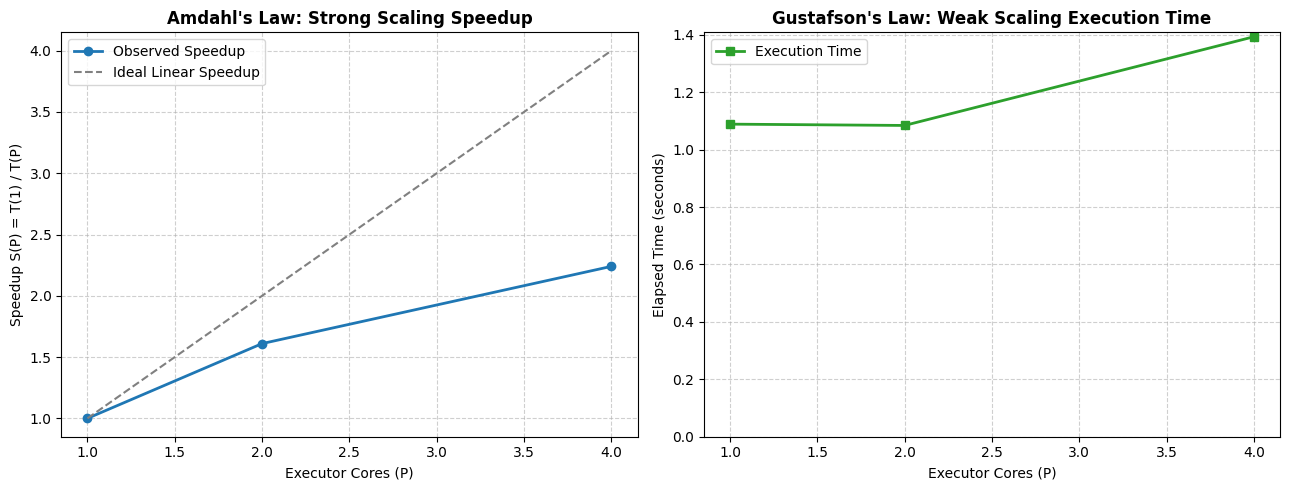

Scaling Curves plot saved to: /content/drive/MyDrive/Flight-Delay-Prediction/benchmarks/scaling_curves.png


In [15]:
# =============================================================================
# Cell 10: Strong & Weak Scaling Benchmarking (DA231o Rubric Requirement)
# =============================================================================
import time
import matplotlib.pyplot as plt

# Stop driver session to cycle through multi-core executor allocations
spark.stop()

scaling_data = []
cores_list = [1, 2, 4]
benchmark_parquet = str(PATHS['features'] / 'departure_bts_weather')

# 1. Strong Scaling: Fixed Dataset Size (300,000 rows), Varying Cores P = 1, 2, 4
print("--- Running Strong Scaling Benchmark (Amdahl's Law) ---")
for p in cores_list:
    bench_spark = (SparkSession.builder
                   .appName(f"StrongScaling_{p}")
                   .master(f"local[{p}]")
                   .config("spark.sql.shuffle.partitions", str(p * 2))
                   .getOrCreate())

    bench_df = bench_spark.read.parquet(benchmark_parquet).limit(300000)

    start_t = time.perf_counter()
    # Benchmark distributed grouping, shuffle, and aggregation workload
    _ = (bench_df.groupBy("Origin", "Reporting_Airline")
         .agg(F.avg("DepDelay"), F.stddev("DepDelay"), F.count("flight_key"))
         .collect())
    elapsed = time.perf_counter() - start_t

    scaling_data.append({'Type': 'Strong', 'Cores': p, 'Workload': 300000, 'Time_Sec': elapsed})
    bench_spark.stop()

# 2. Weak Scaling: Workload Scales Linearly with Cores (100,000 rows per core)
print("\n--- Running Weak Scaling Benchmark (Gustafson's Law) ---")
for p in cores_list:
    bench_spark = (SparkSession.builder
                   .appName(f"WeakScaling_{p}")
                   .master(f"local[{p}]")
                   .config("spark.sql.shuffle.partitions", str(p * 2))
                   .getOrCreate())

    current_workload = p * 100000
    bench_df = bench_spark.read.parquet(benchmark_parquet).limit(current_workload)

    start_t = time.perf_counter()
    _ = (bench_df.groupBy("Origin", "Reporting_Airline")
         .agg(F.avg("DepDelay"), F.stddev("DepDelay"), F.count("flight_key"))
         .collect())
    elapsed = time.perf_counter() - start_t

    scaling_data.append({'Type': 'Weak', 'Cores': p, 'Workload': current_workload, 'Time_Sec': elapsed})
    bench_spark.stop()

bench_results = pd.DataFrame(scaling_data)

# Compute Speedup: S(P) = T(1) / T(P)
t1 = bench_results[(bench_results['Type'] == 'Strong') & (bench_results['Cores'] == 1)]['Time_Sec'].values[0]
bench_results['Speedup'] = bench_results.apply(
    lambda r: round(t1 / r['Time_Sec'], 2) if r['Type'] == 'Strong' else np.nan, axis=1)

bench_csv_path = PATHS['benchmarks'] / 'scaling_benchmarks.csv'
bench_results.to_csv(bench_csv_path, index=False)
display(bench_results)

# Render and Save Publication-Quality Scaling Charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

strong_df = bench_results[bench_results['Type'] == 'Strong']
ax1.plot(strong_df['Cores'], strong_df['Speedup'], marker='o', linewidth=2, color='#1f77b4', label='Observed Speedup')
ax1.plot(strong_df['Cores'], strong_df['Cores'], '--', color='gray', label='Ideal Linear Speedup')
ax1.set_title("Amdahl's Law: Strong Scaling Speedup", fontsize=12, fontweight='bold')
ax1.set_xlabel("Executor Cores (P)", fontsize=10)
ax1.set_ylabel("Speedup S(P) = T(1) / T(P)", fontsize=10)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

weak_df = bench_results[bench_results['Type'] == 'Weak']
ax2.plot(weak_df['Cores'], weak_df['Time_Sec'], marker='s', linewidth=2, color='#2ca02c', label='Execution Time')
ax2.set_title("Gustafson's Law: Weak Scaling Execution Time", fontsize=12, fontweight='bold')
ax2.set_xlabel("Executor Cores (P)", fontsize=10)
ax2.set_ylabel("Elapsed Time (seconds)", fontsize=10)
ax2.set_ylim(bottom=0)
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
scaling_img_path = PATHS['benchmarks'] / 'scaling_curves.png'
plt.savefig(scaling_img_path, dpi=300)
plt.show()
print(f"Scaling Curves plot saved to: {scaling_img_path}")